# **Breast Cancer Classification Using Machine Learning**

**Implementasi Machine Learning Menggunakan Python dan Google Colab**

Pada contoh ini, kita akan membangun model Machine Learning untuk melakukan klasifikasi kanker payudara menggunakan algoritma Logistic Regression.

Dataset yang digunakan adalah Breast Cancer Wisconsin Dataset yang tersedia pada Scikit-learn. Dataset ini memiliki 569 sampel dengan 30 fitur numerik yang menggambarkan karakteristik sel tumor.

Model akan dilatih untuk mengklasifikasikan tumor ke dalam dua kategori:

*   Malignant (0): Tumor ganas.
*   Benign (1): Tumor jinak.

Proses implementasi dilakukan menggunakan Google Colab sehingga mahasiswa tidak perlu melakukan instalasi Python dan library secara manual pada komputer masing-masing.

# **Step 1: Import Libraries**

Tahap pertama adalah mengimpor library Python yang diperlukan untuk proses pengolahan data, visualisasi, pembangunan model Machine Learning, dan evaluasi performa model.

In [30]:
# Library untuk pengolahan data numerik
import numpy as np
import pandas as pd

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil dataset Breast Cancer dari Scikit-learn
from sklearn.datasets import load_breast_cancer

# Library untuk membagi dataset dan normalisasi data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Library untuk membangun pipeline dan model klasifikasi
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# Library untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Semua librari berhasil dimasukkan")

Semua librari berhasil dimasukkan


# **Step 2: Load Dataset**

Pada tahap ini, kita akan memuat Breast Cancer Wisconsin Dataset menggunakan fungsi load_breast_cancer() dari Scikit-learn.

Dataset kemudian dikonversi menjadi DataFrame menggunakan Pandas agar lebih mudah dianalisis.

In [31]:
# Memuat Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Mengambil fitur dan mengubahnya menjadi DataFrame
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Mengambil label atau target kelas
y = data.target

# Menampilkan dimensi dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima sampel pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas target
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

Penjelasan:

*   data.data berisi data numerik yang digunakan sebagai fitur masukan.
*   data.feature_names berisi nama dari masing-masing fitur.
*   data.target berisi label atau kategori tumor.
*   X merupakan variabel yang menyimpan fitur.
*   y merupakan variabel yang menyimpan target klasifikasi.

# **Step 3: Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) merupakan proses eksplorasi dataset untuk memahami karakteristik data sebelum digunakan dalam proses pelatihan model Machine Learning.

Pada tahap ini, kita akan memeriksa:

*   Jumlah sampel pada setiap kelas.
*   Distribusi data.
*   Nilai yang hilang (missing values).
*   Karakteristik fitur yang digunakan.

In [32]:
# Menampilkan informasi umum dataset
print("Dataset Information:")
print(X.info())

# Memeriksa jumlah missing values
print("\nMissing Values:")
print(X.isnull().sum().sum())

# Menampilkan statistik deskriptif
print("\nStatistical Description:")
print(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

Penjelasan:

*   info() menampilkan informasi tipe data dan jumlah data pada setiap fitur.
*   isnull().sum().sum() menghitung total nilai yang hilang.
*   describe() menampilkan statistik deskriptif seperti mean, standar deviasi, minimum, dan maksimum.

**Check Class Distribution**

Selanjutnya, kita akan melihat distribusi jumlah sampel untuk masing-masing kelas tumor.

Class Distribution:
0    212
1    357
Name: count, dtype: int64


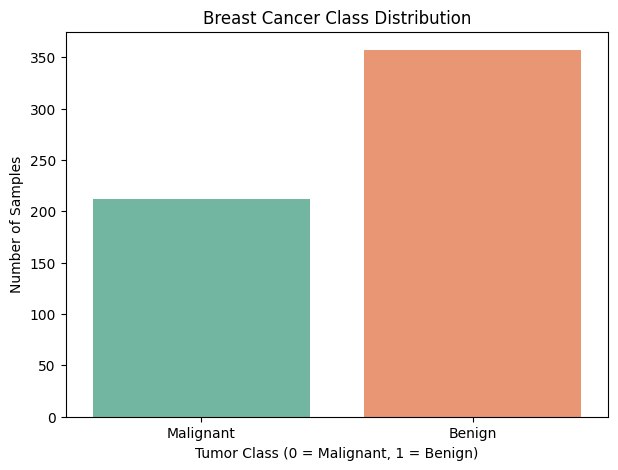

In [33]:
# Menghitung jumlah sampel pada setiap kelas
class_counts = pd.Series(y).value_counts().sort_index()

# Menampilkan jumlah sampel
print("Class Distribution:")
print(class_counts)

# Visualisasi distribusi kelas
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])

plt.show()

Penjelasan:

Visualisasi ini digunakan untuk mengetahui jumlah sampel pada masing-masing kategori.

Informasi distribusi kelas penting karena ketidakseimbangan jumlah sampel dapat memengaruhi proses pelatihan dan evaluasi model.

# **Step 4: Dataset Splitting**

Sebelum membangun model Machine Learning, dataset perlu dibagi menjadi dua bagian:

*   Training Data: Data yang digunakan untuk melatih model.
*   Testing Data: Data yang digunakan untuk menguji kemampuan model terhadap data yang tidak digunakan selama pelatihan.

Pada contoh ini, kita menggunakan pembagian:

*   80% Training Data.
*   20% Testing Data.

In [34]:
# Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Samples: 455
Testing Samples: 114

Training Features: (455, 30)
Testing Features: (114, 30)


Penjelasan parameter:

X: Dataset fitur

y: Label target

test_size=0.2: 20% data digunakan untuk pengujian

random_state=42: Menjaga konsistensi pembagian data

stratify=y: Mempertahankan proporsi kelas pada training dan testing

### **Modifikasi Pembagian Dataset (70% Training, 30% Testing)**

Sesuai instruksi, kita akan mengubah parameter `test_size` menjadi `0.3` (30% data uji).

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Memastikan dataset dimuat
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Melakukan pembagian dataset menjadi 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 398
Testing Samples: 171


# **Step 5: Data Normalization (Feature Scaling)**

Fitur dalam dataset memiliki rentang nilai yang berbeda.

Sebagai contoh:

- Mean Radius memiliki rentang nilai tertentu.
- Mean Area memiliki rentang nilai yang jauh lebih besar.
- Mean Smoothness memiliki rentang nilai yang relatif kecil.

Perbedaan skala tersebut dapat memengaruhi proses optimasi algoritma Machine Learning seperti Logistic Regression.

Oleh karena itu, kita menggunakan StandardScaler untuk melakukan standardisasi fitur.

Standardisasi dilakukan menggunakan persamaan:

$$
z = \frac{x - \mu}{\sigma}
$$

Keterangan:

- $x$ = Nilai fitur awal.
- $\mu$ = Rata-rata fitur.
- $\sigma$ = Standar deviasi fitur.
- $z$ = Nilai fitur setelah standardisasi.

Dalam implementasi ini, StandardScaler akan dimasukkan ke dalam Pipeline agar proses standardisasi dilakukan secara otomatis.

Catatan: StandardScaler hanya mempelajari parameter dari data training. Data testing hanya ditransformasikan menggunakan parameter tersebut untuk mencegah data leakage.

In [36]:
# Membuat pipeline yang menggabungkan standardisasi dan Logistic Regression
model = make_pipeline(
    StandardScaler(),

    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Melatih model menggunakan data training
model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


Penjelasan:

- StandardScaler() melakukan standardisasi fitur.
- LogisticRegression() membangun model klasifikasi.
- max_iter=1000 menentukan jumlah maksimum iterasi optimasi.
- fit() digunakan untuk melatih model berdasarkan data training.

Dengan menggunakan Pipeline, proses standardisasi dan pelatihan model dapat dilakukan dalam satu alur.

### **Step 5b: Pembangunan Model Alternatif (Random Forest Classifier)**

Kita juga akan membangun model klasifikasi menggunakan algoritma **Random Forest Classifier** untuk dibandingkan dengan Logistic Regression.

In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Membangun pipeline untuk Random Forest
rf_model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
)

# Melatih model Random Forest
rf_model.fit(X_train, y_train)
print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


# **Step 6: Model Prediction**

Setelah model berhasil dilatih, langkah berikutnya adalah melakukan prediksi menggunakan data testing.

Model akan menghasilkan prediksi kategori tumor berdasarkan karakteristik fitur yang diberikan.

In [38]:
# Melakukan prediksi menggunakan data testing
y_pred = model.predict(X_test)

# Menampilkan hasil prediksi
print("Predicted Classes:")
print(y_pred)

# Menampilkan label sebenarnya
print("\nActual Classes:")
print(y_test)

Predicted Classes:
[0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]

Actual Classes:
[0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 1 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]


Penjelasan:

- predict() digunakan untuk menghasilkan prediksi kelas.
- y_pred berisi hasil prediksi model.
- y_test berisi kelas sebenarnya dari data testing.

Hasil prediksi kemudian dibandingkan dengan label sebenarnya untuk mengetahui tingkat ketepatan model.

# **Step 7: Model Evaluation**

Evaluasi dilakukan untuk mengukur kemampuan model dalam mengklasifikasikan tumor dengan benar.

Pada praktikum ini, kita menggunakan beberapa metrik evaluasi:

- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.

In [39]:
# Menghitung akurasi model
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.9883040935672515
Model Accuracy (%): 98.83040935672514


**Accuracy**

Accuracy menunjukkan persentase jumlah prediksi yang benar dibandingkan dengan keseluruhan jumlah data pengujian.

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$

Keterangan:

- TP = True Positive.
- TN = True Negative.
- FP = False Positive.
- FN = False Negative.

In [40]:
# Menampilkan classification report
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171



**Precision, Recall, and F1-Score**

Ketiga metrik ini digunakan untuk memahami performa klasifikasi secara lebih detail.

- Precision: Mengukur ketepatan prediksi pada suatu kelas.
- Recall: Mengukur kemampuan model menemukan seluruh sampel dari suatu kelas.
- F1-Score: Harmonic mean antara precision dan recall.

In [41]:
# Mengambil probabilitas prediksi untuk kelas 1 (Benign)
y_probability = model.predict_proba(X_test)[:, 1]

# Menghitung nilai ROC-AUC
auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.9981016355140186


**ROC-AUC**

ROC-AUC digunakan untuk mengukur kemampuan model dalam membedakan dua kelas berdasarkan berbagai nilai threshold.

Nilai AUC berada pada rentang 0 sampai 1.

Semakin mendekati 1, semakin baik kemampuan diskriminasi model.

# **Step 8: Confusion Matrix**

Confusion Matrix merupakan tabel yang digunakan untuk membandingkan hasil prediksi model dengan kelas sebenarnya.

Confusion Matrix memiliki empat komponen utama:
| Komponen | Keterangan |
|:--|:--|
| True Positive (TP) | Sampel positif yang diprediksi positif |
| True Negative (TN) | Sampel negatif yang diprediksi negatif |
| False Positive (FP) | Sampel negatif yang diprediksi positif |
| False Negative (FN) | Sampel positif yang diprediksi negatif |

Pada dataset ini, kelas positif secara default adalah kelas 1 (Benign), sedangkan kelas negatif adalah kelas 0 (Malignant).

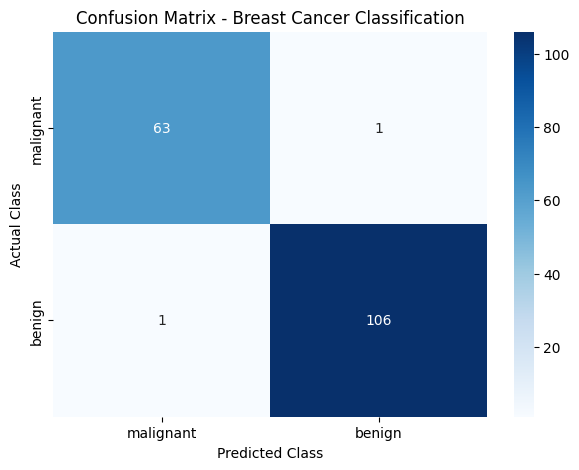

In [42]:
# Menghitung confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualisasi confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix - Breast Cancer Classification")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

Interpretasi:

- Diagonal utama menunjukkan jumlah prediksi yang benar.
- Sel di luar diagonal menunjukkan jumlah kesalahan prediksi.

Dalam konteks klasifikasi kanker, False Negative untuk kelas malignant berarti tumor ganas salah diprediksi sebagai jinak. Kesalahan ini sangat penting untuk diperhatikan karena dapat menyebabkan kondisi berbahaya jika model digunakan dalam konteks klinis.

# **Step 10: Perbandingan Model & Analisis**

Bagian ini membandingkan performa antara **Logistic Regression** dan **Random Forest Classifier** yang dilatih menggunakan data 70:30.

In [43]:
import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pastikan model Logistic Regression telah terdefinisi dan dilatih ulang dengan data 70:30
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
model.fit(X_train, y_train)

# Prediksi dari kedua model
y_pred_lr = model.predict(X_test)
y_prob_lr = model.predict_proba(X_test)[:, 1]

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Hitung Metrik Evaluasi
metrics_data = {
    'Logistic Regression': [
        accuracy_score(y_test, y_pred_lr),
        roc_auc_score(y_test, y_prob_lr)
    ],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf),
        roc_auc_score(y_test, y_prob_rf)
    ]
}

df_compare = pd.DataFrame(metrics_data, index=['Accuracy', 'ROC-AUC'])
display(df_compare)

,Logistic Regression,Random Forest
Accuracy,0.988304,0.935673
ROC-AUC,0.998102,0.991311


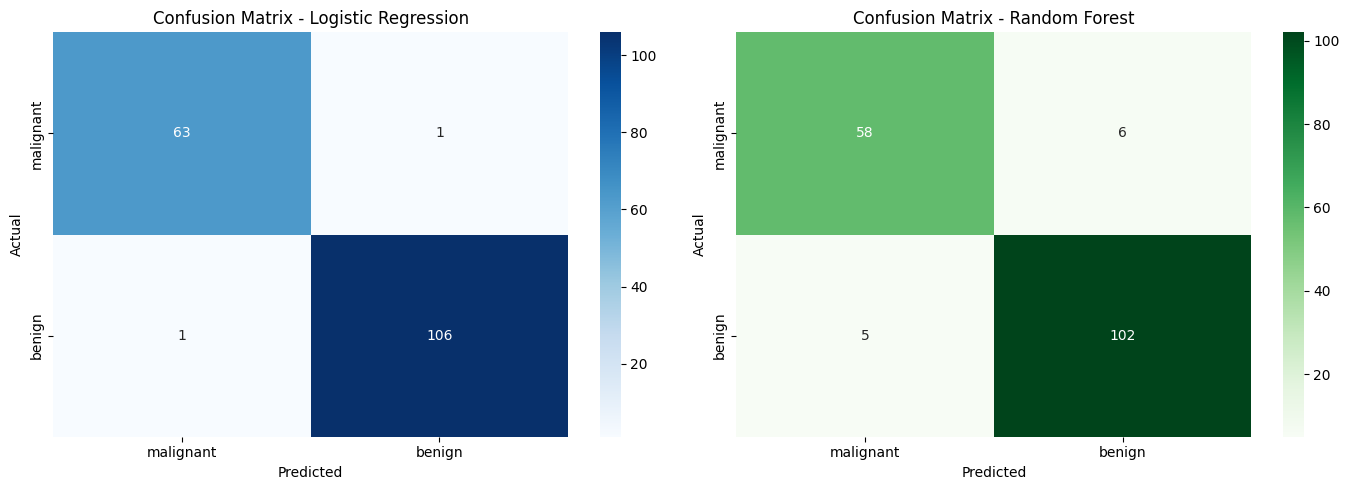

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Perbandingan Confusion Matrix Berdampingan
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap Logistic Regression
sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Blues",
    xticklabels=data.target_names, yticklabels=data.target_names, ax=axes[0]
)
axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Heatmap Random Forest
sns.heatmap(
    cm_rf, annot=True, fmt="d", cmap="Greens",
    xticklabels=data.target_names, yticklabels=data.target_names, ax=axes[1]
)
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

### **Analisis & Pembahasan**

#### **1. Perbandingan Algoritma**
Setelah menjalankan kode di atas, Anda dapat melihat perbandingan performa akurasi dan nilai ROC-AUC secara langsung:
* **Akurasi & AUC**: Model yang memiliki akurasi dan nilai AUC mendekati 1 memiliki kemampuan pemisahan kelas yang lebih baik.
* **Confusion Matrix**: Bandingkan jumlah kesalahan klasifikasi pada masing-masing model, khususnya pada kelas *Malignant* (0).

#### **2. Mengapa Akurasi Saja Tidak Cukup untuk Klasifikasi Kanker?**
Dalam kasus medis seperti deteksi kanker payudara, mengandalkan **Accuracy** saja dapat sangat berbahaya karena:
1. **Bahaya False Negative (FN)**: *False Negative* terjadi ketika seorang pasien yang sebenarnya mengidap tumor ganas (*Malignant*) didiagnosis oleh model sebagai tumor jinak (*Benign*). Hal ini berisiko fatal karena menunda perawatan medis kritis.
2. **Sensitivitas (Recall)**: Kita membutuhkan nilai **Recall (Sensitivity)** yang sangat tinggi untuk kelas *Malignant*. Lebih baik memiliki sedikit *False Positive* (diduga ganas tetapi ternyata jinak, yang dapat dikonfirmasi dengan tes lanjutan) daripada melewatkan satu pun kasus *False Negative*.
3. **Ketidakseimbangan Data (Data Imbalance)**: Jika seandainya dataset memiliki 95% kasus jinak dan hanya 5% ganas, model yang menebak "jinak" untuk semua data akan tetap memiliki akurasi 95%, namun gagal total dalam mendeteksi penderita kanker sesungguhnya.

# **Step 9: Predict a New Sample**

Pada tahap terakhir, kita akan mencoba menggunakan model yang telah dilatih untuk memprediksi satu sampel baru.

Sebagai contoh, kita mengambil satu sampel dari data testing.

In [45]:
sample = X_test.iloc[[0]]

# Menampilkan fitur sampel
print("Input Sample:")
print(sample)

# Melakukan prediksi
prediction = model.predict(sample)[0]

# Mengambil probabilitas prediksi
probability = model.predict_proba(sample)[0]

# Mengubah label numerik menjadi nama kelas
result = data.target_names[prediction]

# Menampilkan hasil prediksi
print("\nPrediction Result:", result)

print("\nPrediction Probability:")

for class_name, prob in zip(data.target_names, probability):

    print(
        class_name,
        ":",
        round(prob * 100, 2),
        "%"
    )

Input Sample:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
14        13.73         22.61            93.6      578.3           0.1131   

    mean compactness  mean concavity  mean concave points  mean symmetry  \
14            0.2293          0.2128              0.08025         0.2069   

    mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
14                 0.07682  ...         15.03          32.01            108.8   

    worst area  worst smoothness  worst compactness  worst concavity  \
14       697.7            0.1651             0.7725           0.6943   

    worst concave points  worst symmetry  worst fractal dimension  
14                0.2208          0.3596                   0.1431  

[1 rows x 30 columns]

Prediction Result: malignant

Prediction Probability:
malignant : 96.79 %
benign : 3.21 %


Penjelasan:

1. X_test.iloc[[0]] mengambil satu sampel dari data testing.
2. predict() menghasilkan kategori hasil klasifikasi.
3. predict_proba() menghasilkan probabilitas prediksi untuk masing-masing kelas.
4. data.target_names mengubah label numerik menjadi nama kategori.

Catatan: Model ini digunakan hanya untuk pembelajaran dan demonstrasi Machine Learning. Hasil prediksi tidak boleh digunakan sebagai pengganti diagnosis medis profesional.